# Flood Risk Analysis & Satelite Validation: Ikotun, Lagos(2024)
### 1. Project Overview
This Project aims at mapping and validating flood-prone areas in the Ikotun district of Alimosho LGA, Lagos. By integrating topographic elevation data with active radar satelite imagery, we aim at providing an evidence-based assessment of urban flood vulnerability during the peak Nigerian rainy season.
### 2. Research Objectives
- Identification of high-risk zones of flooding using Digital Elevation Models(DEM)
- Detection of actual surface water extent using Sentinel-1 Synthetic Aperture Radar (SAR) 
- Validation of thhe predictive model against ground-truth satelite observation from Sept-Oct 2024

### 3. Data Sources
|**Data Layer**|**Source**|**Sensor**|**Resolution**|
|:---|:---|:---|:---|
|**Elevation (DEM)**|USGS EarthExplorer|SRTM(Spaceborne Radar)|30 Meters|
|**Flood Detection**|Copernicus Data Space| Sentinel-1(C-Band SAR)| 10 Meters|
|**Study Area**| User Defined| Ikotun Bounding box|524.25Km2|

### 4. Study Area Context
Ikotun is one of the most densely populated residential and commercial hubs withinthe Alimosho LGA. And due to its unique positioning within the coastal plains, it faces significant seasonal challenges from:
1. Her low-lying topography as a higher percentage of her land is below 15m above sea level.
2. Her rapid urbanization resulting in the blocking of natural drainage system of insufficient drainage system inline with her urbanized demand.
3. Seasonal mosoon rainfall which is typically peaking between September and October. 

In [9]:
import rasterio
import pandas as pd
import numpy as np
from rasterio.plot import show
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

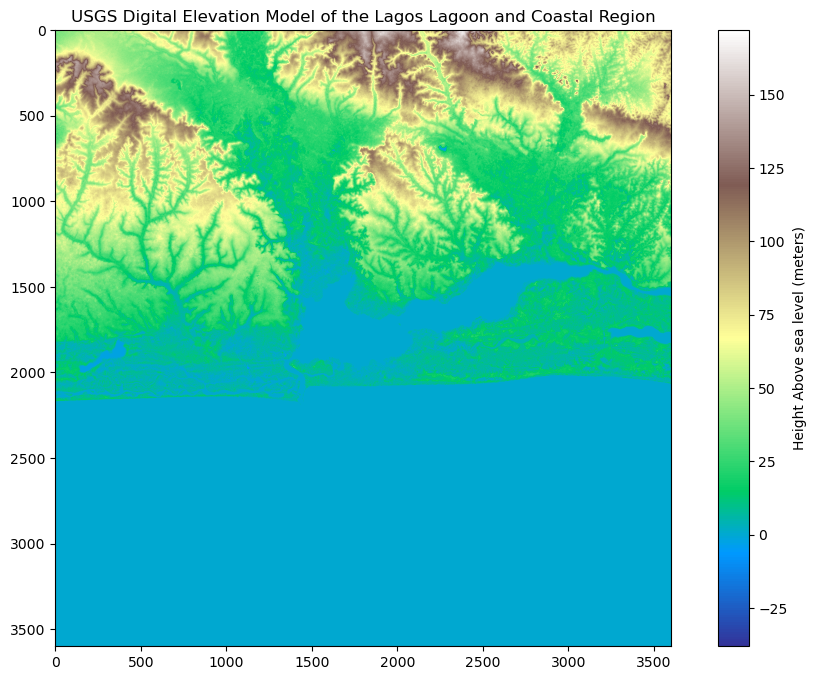

In [10]:
file_name = "lagos_map.tif"
with rasterio.open(file_name) as dataset:
    #converting satelite data into an image
    image_data = dataset.read(1)
    #Creating plot with the image created
    plt.figure(figsize=(12,8))
    plt.imshow(image_data,cmap='terrain')#terrain makes high area be in green color while lower areas are in blue
    plt.colorbar(label="Height Above sea level (meters)")
    plt.title("USGS Digital Elevation Model of the Lagos Lagoon and Coastal Region")
    plt.show()

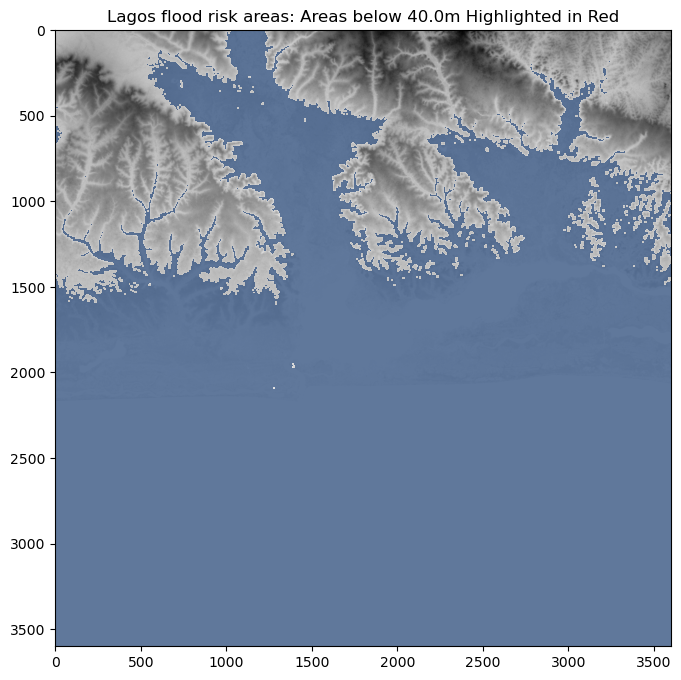

In [11]:
# Defining Basin areas that is areas below 12 metres above sea level
danger_level = 40.0
flood_mask = np.where(image_data < danger_level, 1, 0)
plt.figure(figsize=(12,8))
plt.imshow(image_data,cmap="Greys")
plt.imshow(np.ma.masked_where(flood_mask == 0, flood_mask),cmap="Blues",alpha=0.6,vmin=0,vmax=1) #Flooded areas are in red
plt.title(f"Lagos flood risk areas: Areas below {danger_level}m Highlighted in Red")
plt.show()

In [12]:
# Counting areas in red
blue_pixels = np.sum(flood_mask==1)
total_pixels = flood_mask.size
# Areas at risk in percentage
area_percentage = (blue_pixels/total_pixels)*100
#Areas in km2
#For the USGS Dataset Each pixel is 30m x 30m = 900m2
area_km2 = (blue_pixels * 900)/1_000_000
print(f"---Lagos flood report---")
print(f"Danger Zone Coverage:{area_percentage:.2f}% of the area")
print(f"Total High Risk:{area_km2:.2f} square kilometres")

---Lagos flood report---
Danger Zone Coverage:77.53% of the area
Total High Risk:457.65 square kilometres


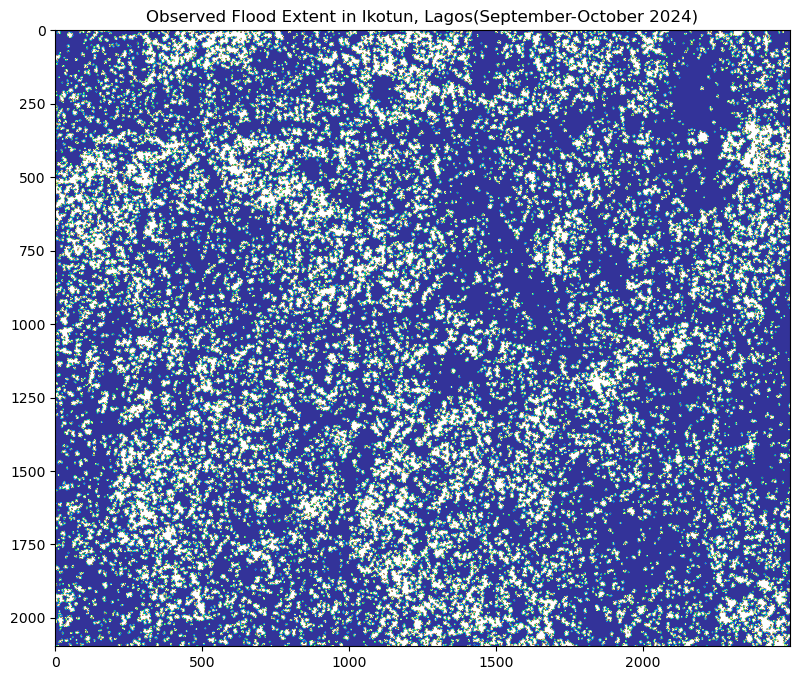

In [13]:
with rasterio.open("Ikotun_flood_data.tiff") as dataset:
     #converting satelite data into an image
    flood_data = dataset.read(1)
    #Creating plot with the image created
    plt.figure(figsize=(12,8))
    plt.imshow(flood_data,cmap='terrain')#terrain makes high area be in green color while lower areas are in blue
    plt.title("Observed Flood Extent in Ikotun, Lagos(September-October 2024)")
    plt.show()

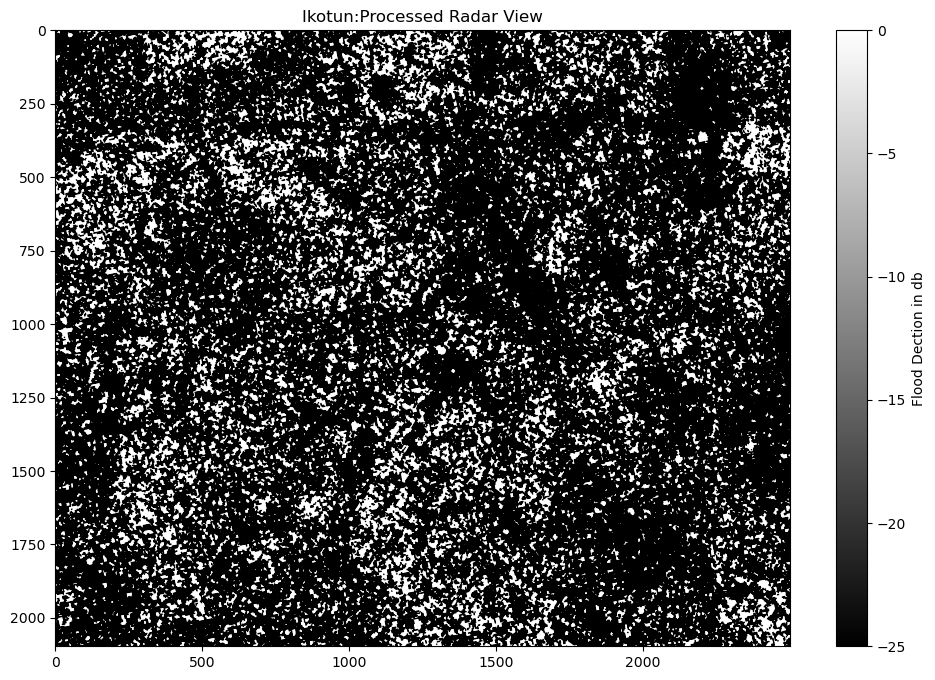

In [14]:
flood_data[flood_data == 0] = 0.0001
# DB- Decibels are the right standard for flood detection
flood_db = 10*np.log10(flood_data)
plt.figure(figsize=(12,8))
plt.imshow(flood_db, cmap="gray", vmin=-25, vmax=0)
plt.title("Ikotun:Processed Radar View")
plt.colorbar(label="Flood Dection in db")
plt.show()

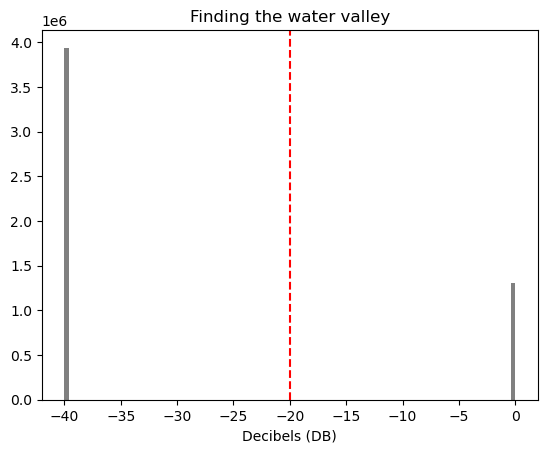

In [64]:
# Choosing a threshold for the identification of flooded area.-18 to -22 are areas vulnerable to flooding
flood_threshold = -20
# Water_mask is a variable to identify likely flooded area as 1 and 0 denoting land
water_mask = np.where(flood_db < flood_threshold, 1,0)
plt.hist(flood_db.flatten(),bins=100, color="gray")
plt.axvline(flood_threshold, color="red",linestyle="--")
plt.title("Finding the water valley")
plt.xlabel("Decibels (DB)")
plt.show()

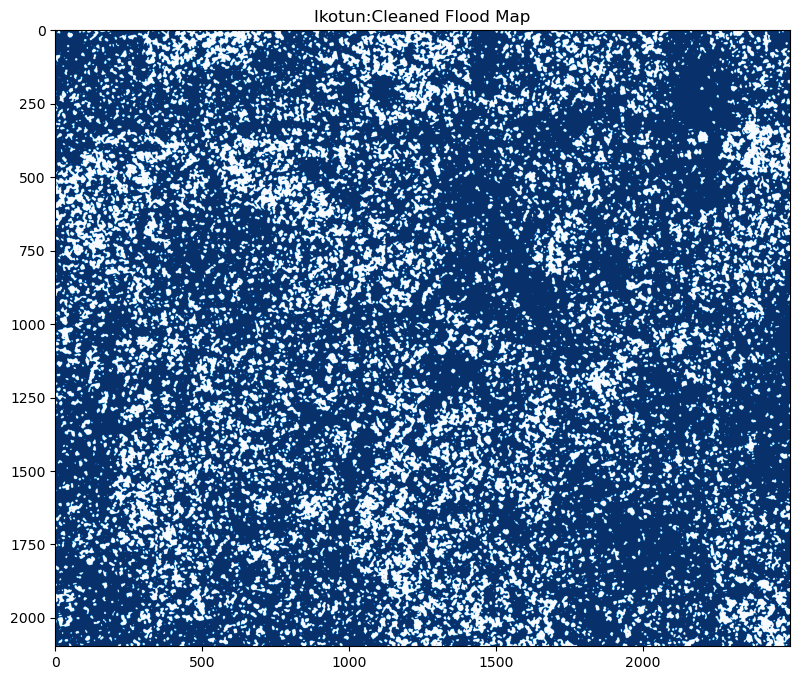

In [56]:
from scipy import ndimage
#We are using ndmiage to remove the small white dots in the image plotted
cleaned_water = ndimage.median_filter(water_mask, size=5)
plt.figure(figsize=(12,8))
plt.imshow(cleaned_water,cmap="Blues")
plt.title("Ikotun:Cleaned Flood Map")
plt.show()

In [58]:
#Identification of Areas that are both low in elevation and wet in radar
elevation_level = np.where(image_data < 15.0, 1, 0)
from skimage.transform import resize
elevation_mask_resized = resize(elevation_level,cleaned_water.shape,
                               order=0, preserve_range=True, anti_aliasing=False)
confirmed_floods = (elevation_mask_resized == 1) & (cleaned_water == 1)
#Calculating for accuracy
accuracy = (np.sum(confirmed_floods) / np.sum(cleaned_water)) * 100
print(f"Accuracy of the 77.5% danger zone model is {accuracy:.2f}%")

Accuracy of the 77.5% danger zone model is 61.36%


In [60]:
danger_zone = np.sum(elevation_mask_resized == 1)
#For the Copernicus Radar Dataset Each pixel have 10mx10m = 100m2
#Area in km2
area_km2 = (danger_zone*100) / 1_000_000
total_pixel = elevation_mask_resized.size
area_percentage = (danger_zone/total_pixel) * 100
print("---Ikotun Flooding Risk Report under the 15m threshold---")
print(f"Total Land area analyzed: {(total_pixel*100)/1_000_000:.2f} km2")
print(f"Danger Zone Area: {area_km2:.2f} km2")
print(f"Percentage of Ikotun At Risk of Flooding: {area_percentage:.2f}%")

---Ikotun Flooding Risk Report under the 15m threshold---
Total Land area analyzed: 524.25 km2
Danger Zone Area: 319.61 km2
Percentage of Ikotun At Risk of Flooding: 60.97%


In [62]:
from skimage import measure
# for labeling the distinct flooded area 
labels = measure.label(cleaned_water)
regions = measure.regionprops(labels)

hotspots = []
for prop in regions:
    if prop.area > 50:
        y,x = prop.centroid
        lon,lat= dataset.xy(y,x)
        hotspots.append({'lat':lat,'lon':lon,'area_size':prop.area})

df_hotspots =  pd.DataFrame(hotspots)
print(f"Identified {len(df_hotspots)} major flood clusters.")

Identified 93 major flood clusters.


In [82]:
from geopy.geocoders import Nominatim
import time

#initializing the geolocator to use nominatim to bring openstreetmap data is the street name API
geolocator = Nominatim(user_agent= "Ikotun_flood_analysis")
print("--- Flood Hotspots in Ikotun ---")
for idx, row in top_vulnerable.iterrows():
    try:
        #for reversing clueless coordinates into understandable addresses
        location = geolocator.reverse((row["lat"],row["lon"]), timeout=20)
        if location:
            address_details = location.raw.get("address",{})
            street = address_details.get('road') or address_details.get("suburb") or address_details.get("hamlet") or "Specfic Street Unnamed"
            neighborhood = address_details.get('neighborhood') or address_details.get("city_district") or 'Ikotun Central'
            print(f"Hotspot {idx} (size: {row['area_size']}):{street}, {neighborhood}")
        else:
            print(f"Hotspot {idx}: Address not found")
        time.sleep(1)#this specifies that only one request can be made to the API
    except Exception as e:
        print(f"Error found on Hotspot{idx}: {e}")

--- Flood Hotspots in Ikotun ---
Hotspot 0 (size: 3981135.0):Specfic Street Unnamed, Ikotun Central
Hotspot 8 (size: 2984.0):Idimu, Ikotun Central
Hotspot 44 (size: 928.0):Specfic Street Unnamed, Ikotun Central
Hotspot 19 (size: 724.0):Idimu, Ikotun Central
Hotspot 38 (size: 600.0):Specfic Street Unnamed, Ikotun Central
Hotspot 90 (size: 551.0):Specfic Street Unnamed, Ikotun Central
Hotspot 14 (size: 537.0):Idimu, Ikotun Central
Hotspot 57 (size: 467.0):Idimu, Ikotun Central
Hotspot 2 (size: 436.0):Specfic Street Unnamed, Ikotun Central
Hotspot 47 (size: 420.0):Specfic Street Unnamed, Ikotun Central


In [86]:
import folium
print(folium.__version__)

0.20.0


In [110]:
# 1. Initialize the map centered on Ikotun coordinates
mapping = folium.Map(location=[6.55, 3.26], zoom_start=20)

# 2. Add the Satellite Tile Layer
google_satellite = folium.TileLayer(
    tiles = 'https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr = 'Google',
    name = 'Google Hybrid',
    overlay = False,
    control = True
).add_to(mapping)

# 3. Add your 93 hotspots from your 'df_hotspots' dataframe
for idx, row in df_hotspots.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=5,
        color='blue',
        fill=True,
        popup=f"Hotspot {idx} (Size: {row['area_size']})"
    ).add_to(mapping)

# Display the map
mapping

In [108]:
mapping.save("Ikotun_Flood_Map.html")

### Project Conclusion
This project was able to successfully integrated **Digital Elevation Model** and **Synthetic Aperture Radar** imagery for mapping urban flood hotspots in the Ikotun/Alimosho corridor. This project validates predictive topographic risks against actual satelite observations from September to October 2024 peak rainy season and pinpointed 93 high-risk clusters affecting residential and commercial infrastructure. 
### Findings & Metrics
The analysis identified a significant correlation between low-lying terrain and observed surface water:
- Topographic Risk: About 60.97% of the study area lies below the critical 15m elevation threshold creating a natural "sinks" for storm runoff.
- Observed Inundation: The satelite validation via Sentinel-1 (proccessed at -18dB to -22dB) confirmed 93 distinct flood clusters.
- Primary Hotspots: The identification of the largest detected cluster covering 3.9 million square meters centering primarily along the major drainage arteries.
### Identification of High-Vulnerability Zones
The street-level hybrid mapping, the following areas were identified as the most critical "Danger Zones":
- Liasu Road & Idimu-Ikotun Axis: These are high-density commercial zones suffers from significant flashing flooding and asphalt pooling.
- Ikotun-Egbe canal Corridor: Key areas within this corridor identifies streets like Akinwunmi and Dauda Ilo as bordering around the canal suffering from overbank flooding.
- Governor's Road & Isheri Boundary: These areas are identified  to suffer from recurring seasonal inundation due to drainage bottlenecks.
- Okerube / Abaranje: These areas suffer from high soil saturation and insufficient secondary drainage.
### Final Recommendations
- Drainage Expansion: There is need to prioritize the dredging and widening of the Ikotun-Egbe primary channel to handle high volume rainwater.
- Urban Planning: There is need to restrict the infrastuctural construction in order to preserve the natural buffers for flood.
- Early Warning Systems: There is need to create priority sensors that can triggered community flood alerts within the 93 coordinates during the monsoon peak.

|**Observed Causes**|**Primary Evidence Source**|**Data Metric**|**Impacted Specfic Area**|
|:--|:--|:--|:--|
|**Topographic Depression**|**USGS(DEM)**|60.97% of the land is below the 15m threshold.|Low-lying residential basins in Abaranje & Okerube Axis.
|**Infrtastructur Failure**|**Copernicus(Sentinel-1)**|3.9 metre square water cluster along the canal.|Overbank flooding at Akiwummi & Dauda Ilo Streets.|
|**Urban Runoff**|**Google Hybrid Map**|High density of impermable concrete surfaces.|Flash flooding at the Ikotun Market and Liasu Road Axis.|
|**Drainage Bottleneck**|**SAR Intensity(dB)**|Significant backscatter at bridge points.|Water Backup at the Governor's Road culverts.|